In [33]:
import pandas as pd

blood_transfusion = pd.read_csv("./dataset/blood_transfusion.csv")
target = blood_transfusion["Class"]
data = blood_transfusion.drop(columns="Class")

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
model = SVC()

pipeline = make_pipeline(
  scaler,
  model
)

In [35]:
from sklearn.model_selection import cross_validate
from sklearn.model_selection import ShuffleSplit

cv = ShuffleSplit(random_state=0)
cv_results = cross_validate(
  model,
  data,
  target,
  cv=cv
)
cv_results = pd.DataFrame(cv_results)
cv_results

,fit_time,score_time,test_score
0,0.010999,0.001999,0.680000
1,0.010004,0.003997,0.746667
2,0.014179,0.002001,0.760000
3,0.011995,0.002004,0.813333
4,0.010997,0.002002,0.733333
5,0.008998,0.001004,0.773333
6,0.008997,0.001999,0.773333
7,0.009000,0.002001,0.800000
8,0.008468,0.002001,0.773333
9,0.009000,0.001000,0.746667


In [36]:
import numpy as np
gammas = np.logspace(-3, 2, num=30)
gammas

array([1.00000000e-03, 1.48735211e-03, 2.21221629e-03, 3.29034456e-03,
       4.89390092e-03, 7.27895384e-03, 1.08263673e-02, 1.61026203e-02,
       2.39502662e-02, 3.56224789e-02, 5.29831691e-02, 7.88046282e-02,
       1.17210230e-01, 1.74332882e-01, 2.59294380e-01, 3.85662042e-01,
       5.73615251e-01, 8.53167852e-01, 1.26896100e+00, 1.88739182e+00,
       2.80721620e+00, 4.17531894e+00, 6.21016942e+00, 9.23670857e+00,
       1.37382380e+01, 2.04335972e+01, 3.03919538e+01, 4.52035366e+01,
       6.72335754e+01, 1.00000000e+02])

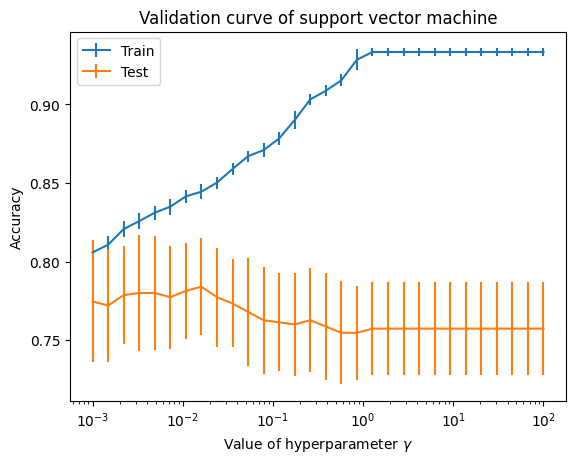

In [37]:
from sklearn.model_selection import ValidationCurveDisplay

display = ValidationCurveDisplay.from_estimator(
  model,
  data,
  target,
  cv=cv,
  param_name="gamma",
  param_range=gammas,
  scoring="accuracy",
  std_display_style="errorbar",
)

_ = display.ax_.set(
    xlabel=r"Value of hyperparameter $\gamma$",
    title="Validation curve of support vector machine",
)

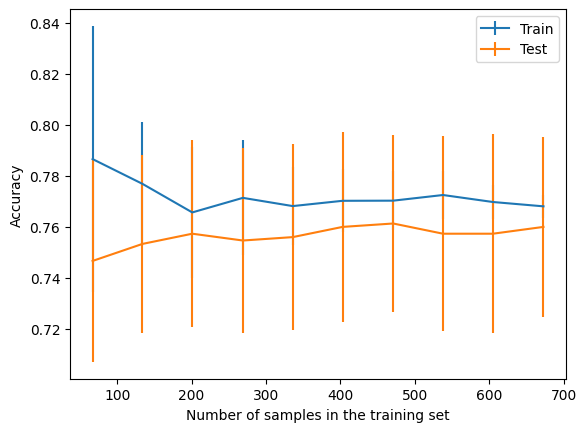

In [38]:
from sklearn.model_selection import LearningCurveDisplay

train_sizes = np.linspace(0.1, 1, num=10)
LearningCurveDisplay.from_estimator(
  model,
  data,
  target,
  train_sizes=train_sizes,
  cv=cv,
  score_type="both",
  score_name="Accuracy",
  std_display_style="errorbar"
)

_ = display.ax_.set(title="Learning curve for support vector machine")